# **Project Name** -    Integrated Retail Analytics for Store Optimization and Demand Forecasting

##### **Project Type**    - EDA / Regression / Unsupervised (Multi-part)
##### **Contribution**    - Individual

# **Project Summary -**

This project analyzes 3 years of weekly sales data from 45 Walmart stores (81 departments each) to build an
integrated retail analytics system covering anomaly detection, time-based sales analysis, store/department
segmentation, market basket-style association analysis, and demand forecasting.

The data comes from three sources: a sales table (Store, Dept, Date, Weekly_Sales, IsHoliday), a stores table
(Store Type A/B/C and Size in sq. ft.), and a features table (Temperature, Fuel_Price, 5 MarkDown promotional
columns, CPI, and Unemployment, all at Store-Date level). These were merged into a single analysis-ready
dataframe of 421,570 rows keyed on Store + Dept + Date.

This notebook covers the EDA phase: cleaning, feature engineering, and 15 charts that build understanding of
how sales behave across stores, departments, time, holidays, markdowns, and macroeconomic conditions - before
any modeling is attempted.

Key cleaning decisions: the 5 MarkDown columns are ~65% missing because most stores didn't run markdown promotions
in earlier weeks of the data (markdowns were only introduced partway through); missing values here are filled
with 0 rather than a mean/median, since "no markdown" is a real, meaningful state, not a random gap. A handful of
negative markdown values (data entry artifacts) are clipped to 0. CPI and Unemployment have a small number of
missing rows concentrated near the end of the feature table's date range; since these are slow-moving macro
indicators, they are forward-filled (then back-filled) within each store rather than imputed with a global mean,
which would distort the trend.

Feature engineering adds Year, Month, Week, and Day extracted from the Date column (needed for seasonality and
holiday-proximity analysis later), a Total_MarkDown and Has_MarkDown flag (summarizing the 5 markdown columns
into one usable signal), and a Negative_Sales_Flag (some Weekly_Sales values are negative, which likely reflects
returns exceeding sales in a given week - these are flagged, not deleted, since they are real retail events).

The EDA surfaces several patterns that carry into later phases: strong right-skew in Weekly_Sales with a long
tail driven by a small number of high-volume store-department combinations; a clear holiday sales lift
(Thanksgiving and Christmas weeks especially); Store Type A stores consistently outselling Type B and C, closely
tracking Store Size; and department-level concentration, where a small subset of departments account for a
disproportionate share of total sales. These findings directly motivate the anomaly detection (holiday spikes vs
genuine anomalies), segmentation (Store Type / Size as natural clustering signals), and forecasting phases
(Store, Dept, Size, IsHoliday, and markdown activity as candidate predictive features) that follow this notebook.

# **GitHub Link -**

https://github.com/mirohit/Integrated-retail-analytics-capstone-project

# **Problem Statement**


Retail chains operate hundreds of stores and thousands of store-department combinations, each with its own
sales rhythm driven by seasonality, holidays, regional economic conditions, and promotional markdowns. Manually
tracking anomalies, forecasting demand, and deciding which stores/departments behave similarly is infeasible at
this scale. The business problem is to use historical sales, store attributes, and external economic indicators
to (a) flag abnormal sales behavior early, (b) understand seasonal and holiday demand patterns, (c) group
stores/departments with similar behavior for targeted strategy, (d) infer which departments' sales move together
(for cross-selling / planogram decisions), and (e) forecast future weekly demand per store-department - all of
which feed into better inventory allocation, staffing, and marketing decisions.

#### **Define Your Business Objective?**

To build a data-driven decision support system for retail store optimization: detect abnormal sales patterns,
understand time and holiday effects on demand, segment stores/departments by behavior, uncover department-level
product association signals, and forecast weekly demand - so the business can plan inventory, markdowns, and
marketing more precisely instead of relying on flat, store-wide assumptions.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [90]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

### Dataset Loading

In [ ]:
# Load Dataset
# Three raw source files, merged into one analysis-ready dataframe

sales = pd.read_csv(r"C:\Users\Rohit Sagar Chavan\Music\ML Engineering\Integrated Retail Analytics for Store Optimization(Advance Machine Learning)\Capston EDA\Input data sets\sales data-set.csv")
stores = pd.read_csv(r"C:\Users\Rohit Sagar Chavan\Music\ML Engineering\Integrated Retail Analytics for Store Optimization(Advance Machine Learning)\Capston EDA\Input data sets\stores data-set.csv")
features = pd.read_csv(r"C:\Users\Rohit Sagar Chavan\Music\ML Engineering\Integrated Retail Analytics for Store Optimization(Advance Machine Learning)\Capston EDA\Input data sets\Features data set.csv")

# Parse dates (dd/mm/yyyy format in the raw files)
sales['Date'] = pd.to_datetime(sales['Date'], format='%d/%m/%Y')
features['Date'] = pd.to_datetime(features['Date'], format='%d/%m/%Y')

# features has its own IsHoliday column (identical to sales' one) - drop before merging to avoid a duplicate/suffix
features_trimmed = features.drop(columns=['IsHoliday'])

# Merge: sales + stores (on Store), then + features (on Store, Date)
df = sales.merge(stores, on='Store', how='left')
df = df.merge(features_trimmed, on=['Store', 'Date'], how='left')
print("Merged dataset shape:", df.shape)

Merged dataset shape: (421570, 16)


### Dataset First View

In [92]:
# Dataset First Look
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106


### Dataset Rows & Columns count

In [93]:
# Dataset Rows & Columns count
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 421570
Columns: 16


### Dataset Information

In [94]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[ns]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
 5   Type          421570 non-null  object        
 6   Size          421570 non-null  int64         
 7   Temperature   421570 non-null  float64       
 8   Fuel_Price    421570 non-null  float64       
 9   MarkDown1     150681 non-null  float64       
 10  MarkDown2     111248 non-null  float64       
 11  MarkDown3     137091 non-null  float64       
 12  MarkDown4     134967 non-null  float64       
 13  MarkDown5     151432 non-null  float64       
 14  CPI           421570 non-null  float64       
 15  Unemployment  421

#### Duplicate Values

In [95]:
# Dataset Duplicate Value Count
duplicate_count = df.duplicated(subset=['Store', 'Dept', 'Date']).sum()
print(f"Duplicate Store-Dept-Date rows: {duplicate_count}")

Duplicate Store-Dept-Date rows: 0


#### Missing Values/Null Values

In [96]:
# Missing Values/Null Values Count
df.isnull().sum()

Store                0
Dept                 0
Date                 0
Weekly_Sales         0
IsHoliday            0
Type                 0
Size                 0
Temperature          0
Fuel_Price           0
MarkDown1       270889
MarkDown2       310322
MarkDown3       284479
MarkDown4       286603
MarkDown5       270138
CPI                  0
Unemployment         0
dtype: int64

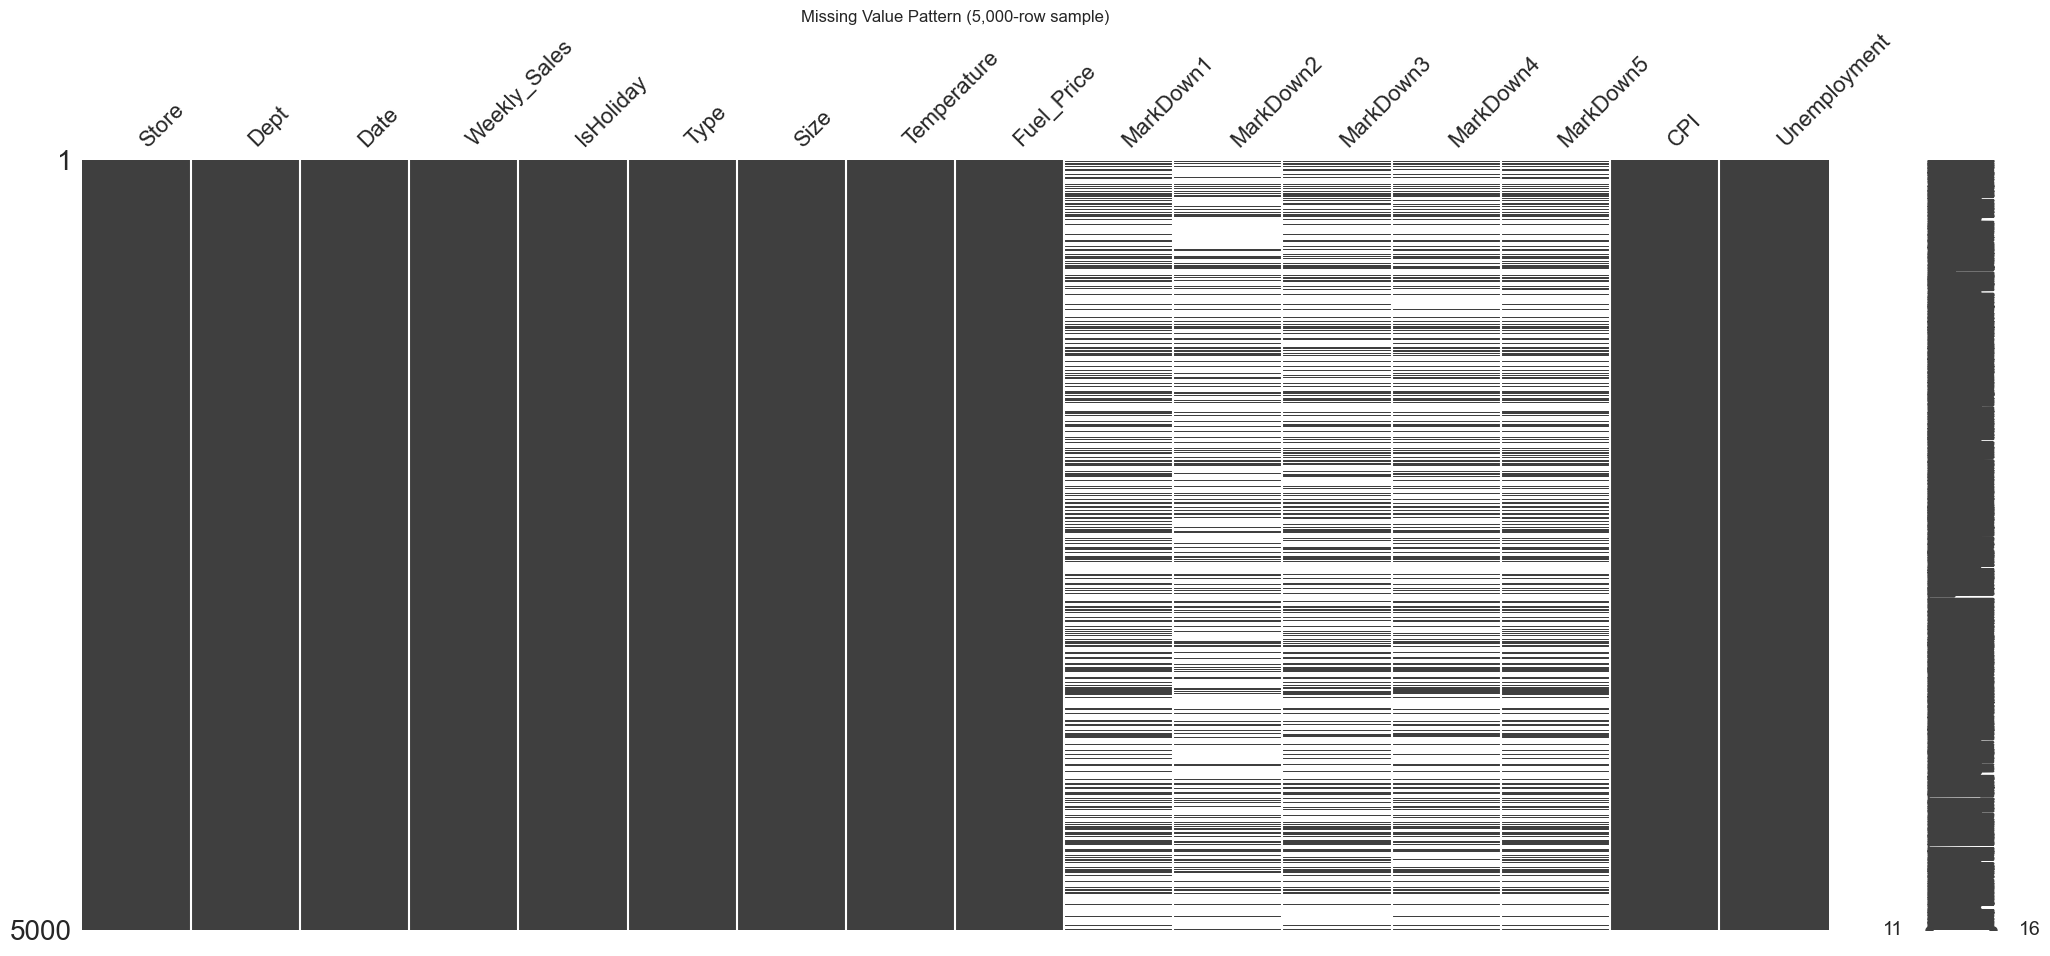

In [97]:
# Visualizing the missing values
msno.matrix(df.sample(5000, random_state=42))
plt.title("Missing Value Pattern (5,000-row sample)")
plt.show()

### What did you know about your dataset?

This is a merged retail dataset of 421,570 weekly Store-Dept sales records spanning Feb 2010 to Oct 2012, across
45 stores and 81 departments. There are no duplicate Store-Dept-Date combinations, so each row is a genuine
distinct weekly observation. The only missing values are in the 5 MarkDown columns (roughly 60-65% missing each,
because markdown promotions were only introduced partway through the data collection window) and in a small
number of CPI/Unemployment rows (features data ends slightly earlier than the sales data for some stores). Every
other column - sales, holiday flag, store type/size, temperature, fuel price - is fully populated.

## ***2. Understanding Your Variables***

In [98]:
# Dataset Columns
df.columns.tolist()

['Store',
 'Dept',
 'Date',
 'Weekly_Sales',
 'IsHoliday',
 'Type',
 'Size',
 'Temperature',
 'Fuel_Price',
 'MarkDown1',
 'MarkDown2',
 'MarkDown3',
 'MarkDown4',
 'MarkDown5',
 'CPI',
 'Unemployment']

In [99]:
# Dataset Describe
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Store,421570.0,NaN,NaN,NaN,22.200546,1.0,11.0,22.0,33.0,45.0,12.785297
Dept,421570.0,NaN,NaN,NaN,44.260317,1.0,18.0,37.0,74.0,99.0,30.492054
Date,421570,NaN,NaN,NaN,2011-06-18 08:30:31.963375104,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,421570.0,NaN,NaN,NaN,15981.258123,-4988.94,2079.65,7612.03,20205.8525,693099.36,22711.183519
IsHoliday,421570,2,False,391909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,421570,3,A,215478,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,421570.0,NaN,NaN,NaN,136727.915739,34875.0,93638.0,140167.0,202505.0,219622.0,60980.583328
Temperature,421570.0,NaN,NaN,NaN,60.090059,-2.06,46.68,62.09,74.28,100.14,18.447931
Fuel_Price,421570.0,NaN,NaN,NaN,3.361027,2.472,2.933,3.452,3.738,4.468,0.458515
MarkDown1,150681.0,NaN,NaN,NaN,7246.420196,0.27,2240.27,5347.45,9210.9,88646.76,8291.221345


### Variables Description

- **Store**: Store ID (1-45)
- **Dept**: Department ID (1-81, not all present in every store)
- **Date**: Week-ending date of the sales record
- **Weekly_Sales**: Total sales for that store-department-week (target variable for forecasting)
- **IsHoliday**: Whether the week contains a major US holiday
- **Type**: Store format - A (largest), B (mid-size), C (smallest)
- **Size**: Store square footage
- **Temperature**: Average regional temperature that week
- **Fuel_Price**: Regional fuel price that week
- **MarkDown1-5**: Anonymized promotional markdown amounts (5 separate promotion types)
- **CPI**: Consumer Price Index for the region
- **Unemployment**: Regional unemployment rate
- **Year/Month/Week/Day**: Engineered from Date

### Check Unique Values for each variable.

In [100]:
# Check Unique Values for each variable.
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

Store: 45 unique values
Dept: 81 unique values
Date: 143 unique values
Weekly_Sales: 359464 unique values
IsHoliday: 2 unique values
Type: 3 unique values
Size: 40 unique values
Temperature: 3528 unique values
Fuel_Price: 892 unique values
MarkDown1: 2277 unique values
MarkDown2: 1499 unique values
MarkDown3: 1662 unique values
MarkDown4: 1944 unique values
MarkDown5: 2293 unique values
CPI: 2145 unique values
Unemployment: 349 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.

# 1. MarkDown columns: missing = "no markdown running" (not a random gap) -> fill with 0
markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
df[markdown_cols] = df[markdown_cols].fillna(0)
# a few negative values are data entry errors -> clip to 0
df[markdown_cols] = df[markdown_cols].clip(lower=0)

# 2. Total markdown activity + a simple binary flag
df['Total_MarkDown'] = df[markdown_cols].sum(axis=1)
df['Has_MarkDown'] = (df['Total_MarkDown'] > 0).astype(int)

# 3. CPI / Unemployment: slow-moving macro indicators -> forward/back-fill within each store (time-ordered)
df = df.sort_values(['Store', 'Date'])
df['CPI'] = df.groupby('Store')['CPI'].transform(lambda s: s.ffill().bfill())
df['Unemployment'] = df.groupby('Store')['Unemployment'].transform(lambda s: s.ffill().bfill())

# 4. Date-based features for seasonality / holiday analysis
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
df['Day'] = df['Date'].dt.day

# 5. Flag (not drop) negative sales - real retail events (returns > sales in a week), useful for anomaly phase
df['Negative_Sales_Flag'] = (df['Weekly_Sales'] < 0).astype(int)

print("Remaining nulls:\n", df.isnull().sum().sum())
print("Shape after wrangling:", df.shape)
df.to_csv(r"C:\Users\Rohit Sagar Chavan\Music\ML Engineering\Integrated Retail Analytics for Store Optimization(Advance Machine Learning)\Capston EDA\Final data set\Final_merged_dataset.csv", index=False)
df.head()

Remaining nulls:
 0
Shape after wrangling: (421570, 23)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,...,MarkDown5,CPI,Unemployment,Total_MarkDown,Has_MarkDown,Year,Month,Week,Day,Negative_Sales_Flag
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,0.0,...,0.0,211.096358,8.106,0.0,0,2010,2,5,5,0
143,1,2,2010-02-05,50605.27,False,A,151315,42.31,2.572,0.0,...,0.0,211.096358,8.106,0.0,0,2010,2,5,5,0
286,1,3,2010-02-05,13740.12,False,A,151315,42.31,2.572,0.0,...,0.0,211.096358,8.106,0.0,0,2010,2,5,5,0
429,1,4,2010-02-05,39954.04,False,A,151315,42.31,2.572,0.0,...,0.0,211.096358,8.106,0.0,0,2010,2,5,5,0
572,1,5,2010-02-05,32229.38,False,A,151315,42.31,2.572,0.0,...,0.0,211.096358,8.106,0.0,0,2010,2,5,5,0


In [102]:
df

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,...,MarkDown5,CPI,Unemployment,Total_MarkDown,Has_MarkDown,Year,Month,Week,Day,Negative_Sales_Flag
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,0.00,...,0.00,211.096358,8.106,0.00,0,2010,2,5,5,0
143,1,2,2010-02-05,50605.27,False,A,151315,42.31,2.572,0.00,...,0.00,211.096358,8.106,0.00,0,2010,2,5,5,0
286,1,3,2010-02-05,13740.12,False,A,151315,42.31,2.572,0.00,...,0.00,211.096358,8.106,0.00,0,2010,2,5,5,0
429,1,4,2010-02-05,39954.04,False,A,151315,42.31,2.572,0.00,...,0.00,211.096358,8.106,0.00,0,2010,2,5,5,0
572,1,5,2010-02-05,32229.38,False,A,151315,42.31,2.572,0.00,...,0.00,211.096358,8.106,0.00,0,2010,2,5,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421012,45,93,2012-10-26,2487.80,False,B,118221,58.85,3.882,4018.91,...,858.33,192.308899,8.667,5247.26,1,2012,10,43,26,0
421146,45,94,2012-10-26,5203.31,False,B,118221,58.85,3.882,4018.91,...,858.33,192.308899,8.667,5247.26,1,2012,10,43,26,0
421289,45,95,2012-10-26,56017.47,False,B,118221,58.85,3.882,4018.91,...,858.33,192.308899,8.667,5247.26,1,2012,10,43,26,0
421434,45,97,2012-10-26,6817.48,False,B,118221,58.85,3.882,4018.91,...,858.33,192.308899,8.667,5247.26,1,2012,10,43,26,0


### What all manipulations have you done and insights you found?

MarkDown NAs were filled with 0 (absence of a promotion, not missing information) rather than mean/median, which
would have fabricated fake markdown activity for weeks where none occurred. CPI/Unemployment gaps were filled by
carrying forward the last known value per store, preserving each store's actual macro trend instead of blending
in unrelated stores' averages. Total_MarkDown and Has_MarkDown were engineered because 5 separate sparse markdown
columns are hard to use directly - a single "markdown intensity" and "markdown active" signal is far more usable
for later modeling. Year/Month/Week were extracted because holiday and seasonal effects are a core part of this
project's business question. Negative sales weeks (about 0.3% of rows) were flagged rather than removed, since
they represent genuine store-level events (heavy returns) worth investigating in the anomaly detection phase
rather than discarding as errors.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

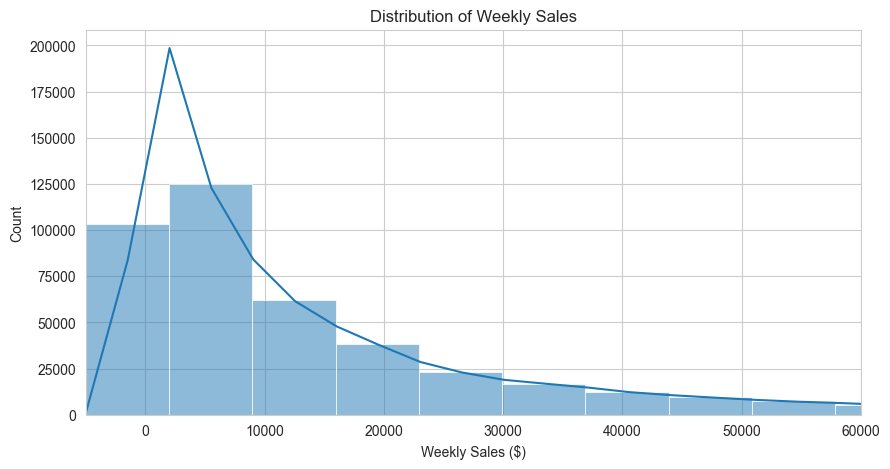

In [103]:
# Chart - 1 visualization code
plt.figure(figsize=(10,5))
sns.histplot(df['Weekly_Sales'], bins=100, kde=True)
plt.xlim(-5000, 60000)
plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram is the most direct way to see the overall shape of the target variable - Weekly_Sales - before any modeling. Understanding skew and spread upfront prevents surprises later during forecasting.

##### 2. What is/are the insight(s) found from the chart?

Weekly_Sales is heavily right-skewed: most store-department-weeks sell in a modest range, but a long tail of high-volume combinations pulls the distribution far to the right. A small number of rows are negative (returns exceeding sales that week).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, positively. It confirms a log-transform or tree-based model (robust to skew) will work better than a plain linear model for forecasting. No negative impact - it's a diagnostic finding, not a risk.

#### Chart - 2

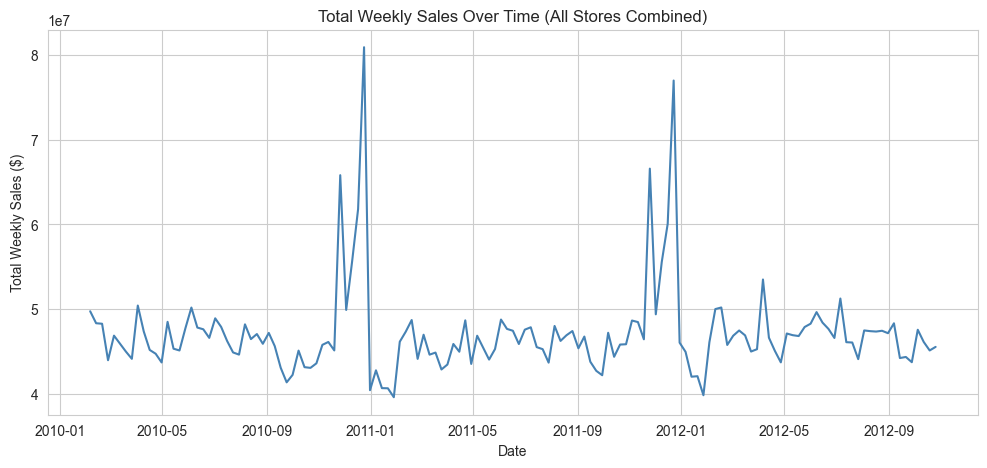

In [104]:
# Chart - 2 visualization code
weekly_total = df.groupby('Date')['Weekly_Sales'].sum().reset_index()
plt.figure(figsize=(12,5))
plt.plot(weekly_total['Date'], weekly_total['Weekly_Sales'], color='steelblue')
plt.title('Total Weekly Sales Over Time (All Stores Combined)')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

A line chart is the standard way to reveal trend and seasonality over time, which is central to both the time-based anomaly detection and forecasting phases of this project.

##### 2. What is/are the insight(s) found from the chart?

Sharp, repeating spikes appear every November-December (Thanksgiving/Christmas shopping), confirming strong holiday seasonality. Sales otherwise fluctuate in a fairly stable band across the 3 years, with no long-term growth or decline trend.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - this directly supports adding holiday-proximity features to forecasting models and confirms holiday weeks should be treated as expected spikes, not anomalies, during anomaly detection.

#### Chart - 3

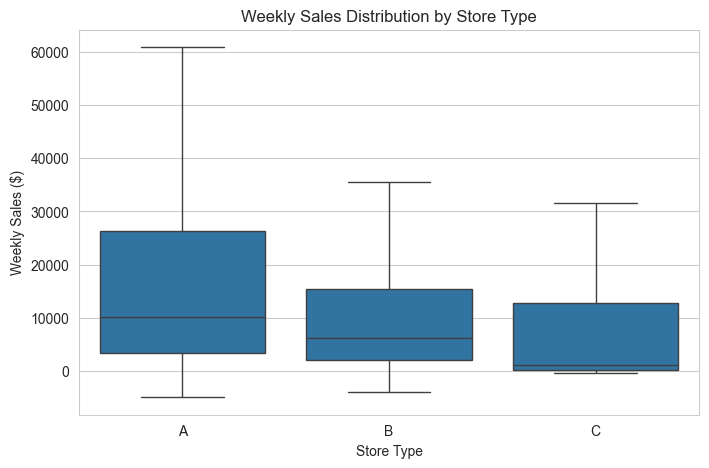

In [105]:
# Chart - 3 visualization code
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Type', y='Weekly_Sales', order=['A','B','C'], showfliers=False)
plt.title('Weekly Sales Distribution by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

Store Type (A/B/C) is a key business segmentation already used by the retailer, so comparing sales across types is a natural first cut before building a data-driven segmentation later in the project.

##### 2. What is/are the insight(s) found from the chart?

Type A stores have noticeably higher median weekly sales than Type B, which in turn outsell Type C. This ordering matches store size (A stores are the largest format).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - suggests Store Type/Size should be included as a forecasting feature, and confirms Type is a reasonable starting point for store segmentation strategy.

#### Chart - 4

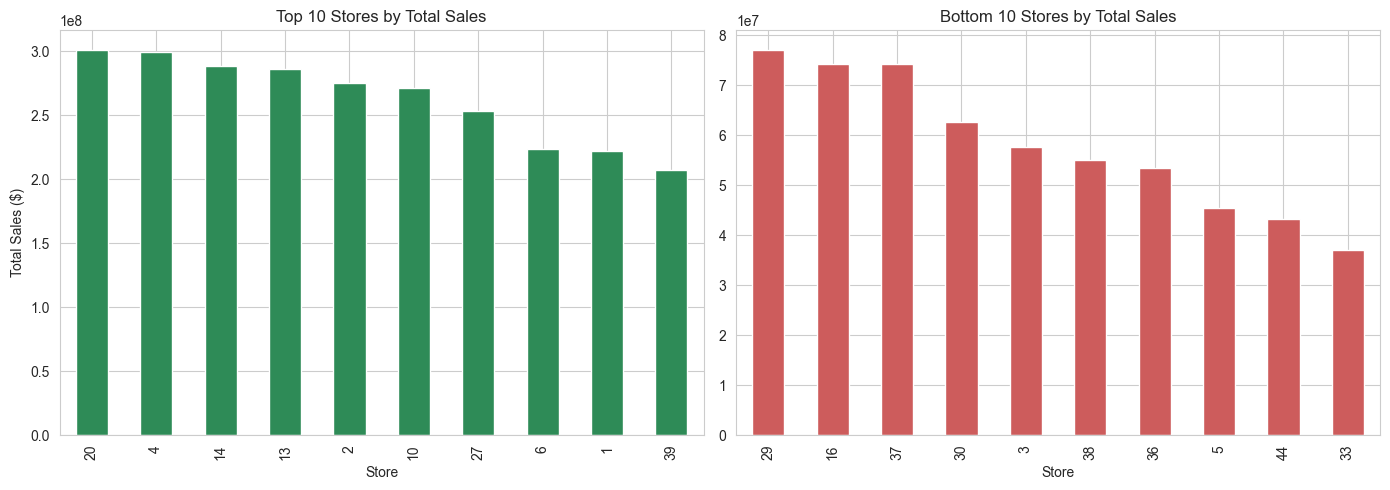

In [106]:
# Chart - 4 visualization code
store_sales = df.groupby('Store')['Weekly_Sales'].sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14,5))
store_sales.head(10).plot(kind='bar', ax=axes[0], color='seagreen')
axes[0].set_title('Top 10 Stores by Total Sales')
axes[0].set_ylabel('Total Sales ($)')
store_sales.tail(10).plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('Bottom 10 Stores by Total Sales')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart ranks stores directly, making it easy to spot which locations drive the most/least revenue - directly useful for store-level strategy and resource allocation.

##### 2. What is/are the insight(s) found from the chart?

Total sales vary dramatically across stores - the top stores generate several times more revenue than the bottom ones, and this gap lines up closely with store Size and Type.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - low-performing stores are candidates for a deeper look (inventory mix, regional economic factors) as part of the store optimization strategy; no negative impact from this finding itself.

#### Chart - 5

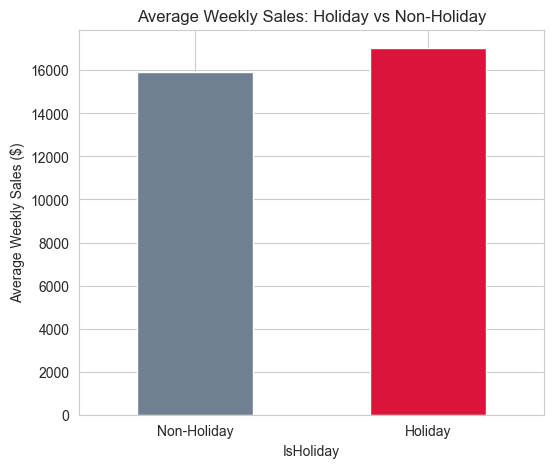

In [107]:
# Chart - 5 visualization code
holiday_avg = df.groupby('IsHoliday')['Weekly_Sales'].mean()
plt.figure(figsize=(6,5))
holiday_avg.plot(kind='bar', color=['slategray','crimson'])
plt.xticks([0,1], ['Non-Holiday','Holiday'], rotation=0)
plt.title('Average Weekly Sales: Holiday vs Non-Holiday')
plt.ylabel('Average Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

A simple bar comparison quantifies the holiday effect that was visually apparent in the time trend chart, turning it into a concrete, usable number.

##### 2. What is/are the insight(s) found from the chart?

Average weekly sales during holiday weeks are meaningfully higher than non-holiday weeks, confirming a real and sizeable holiday lift across the chain.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - supports building holiday-specific inventory/staffing plans and weighting holiday weeks more heavily in forecast evaluation (as the original Walmart competition's WMAE metric does).

#### Chart - 6

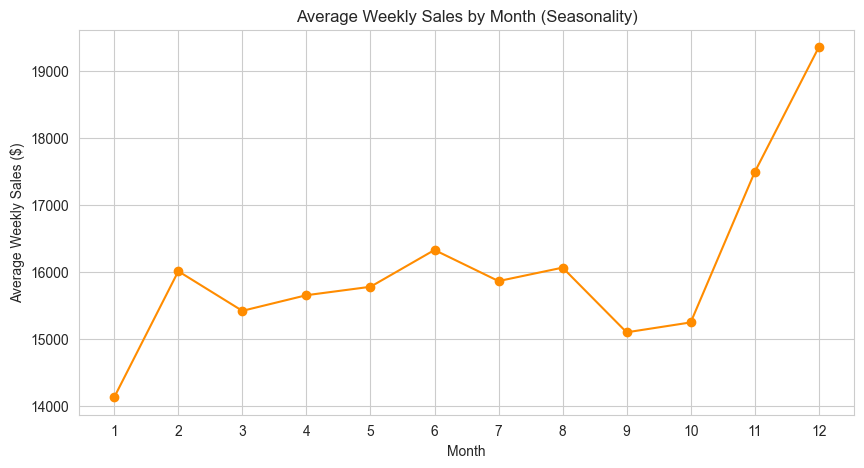

In [108]:
# Chart - 6 visualization code
monthly_avg = df.groupby('Month')['Weekly_Sales'].mean()
plt.figure(figsize=(10,5))
monthly_avg.plot(kind='line', marker='o', color='darkorange')
plt.title('Average Weekly Sales by Month (Seasonality)')
plt.xlabel('Month')
plt.ylabel('Average Weekly Sales ($)')
plt.xticks(range(1,13))
plt.show()

##### 1. Why did you pick the specific chart?

Aggregating by calendar month isolates the seasonal pattern from the noisier week-level trend, useful for understanding demand cycles independent of any single year.

##### 2. What is/are the insight(s) found from the chart?

Sales rise steadily toward November-December and dip in January-February right after the holiday season, showing a clear annual seasonal cycle rather than random fluctuation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - this seasonal pattern should be built into forecasting (month as a feature) and inventory planning (pre-building stock ahead of Q4).

#### Chart - 7

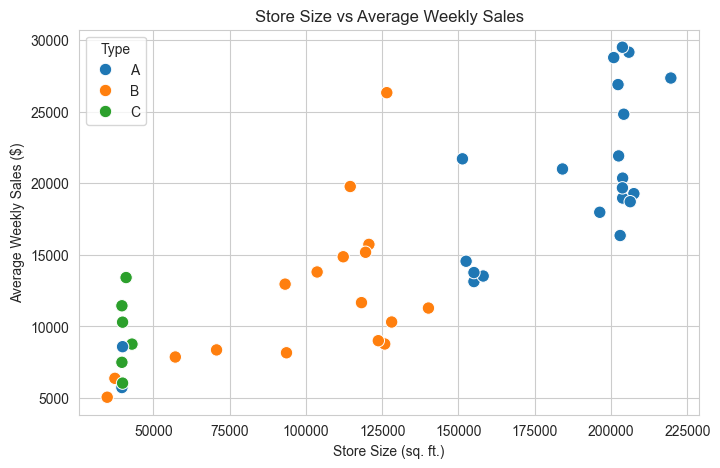

In [109]:
# Chart - 7 visualization code
store_level = df.groupby('Store').agg({'Weekly_Sales':'mean','Size':'first','Type':'first'}).reset_index()
plt.figure(figsize=(8,5))
sns.scatterplot(data=store_level, x='Size', y='Weekly_Sales', hue='Type', s=80)
plt.title('Store Size vs Average Weekly Sales')
plt.xlabel('Store Size (sq. ft.)')
plt.ylabel('Average Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is ideal for checking the relationship between a continuous store attribute (Size) and sales performance, and coloring by Type shows whether the two segmentations agree.

##### 2. What is/are the insight(s) found from the chart?

There's a clear positive relationship between store size and average sales, and larger stores are almost always Type A - confirming Size is a strong, largely redundant proxy for Type.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - for modeling, Size and Type carry overlapping information, so feature selection later should watch for this redundancy rather than treating them as fully independent signals.

#### Chart - 8

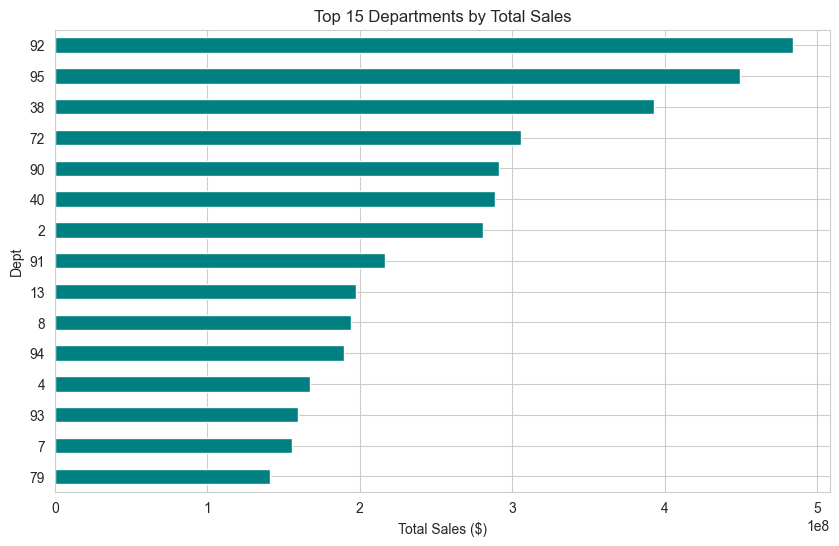

In [110]:
# Chart - 8 visualization code
dept_sales = df.groupby('Dept')['Weekly_Sales'].sum().sort_values(ascending=False).head(15)
plt.figure(figsize=(10,6))
dept_sales.plot(kind='barh', color='teal')
plt.title('Top 15 Departments by Total Sales')
plt.xlabel('Total Sales ($)')
plt.gca().invert_yaxis()
plt.show()

##### 1. Why did you pick the specific chart?

Ranking departments highlights concentration of revenue - essential context before attempting department-level market basket / association analysis later in the project.

##### 2. What is/are the insight(s) found from the chart?

A small number of departments account for a disproportionately large share of total sales, while many departments contribute comparatively little - a classic 80/20 pattern.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - high-revenue departments deserve priority in inventory accuracy and forecasting effort; this also flags which departments matter most for cross-selling strategy.

#### Chart - 9

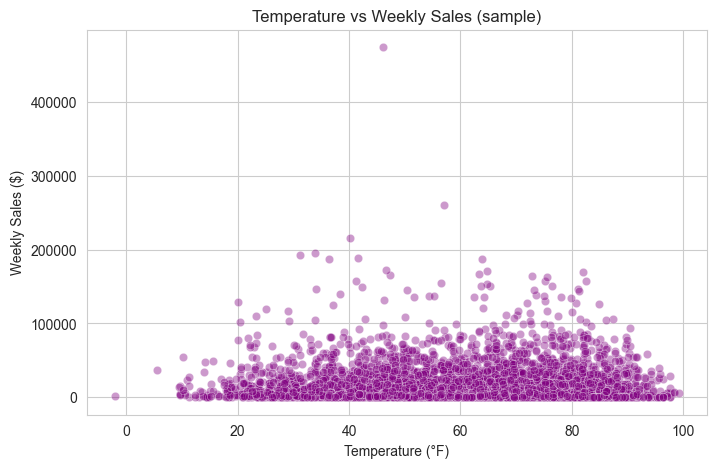

In [111]:
# Chart - 9 visualization code
sample = df.sample(5000, random_state=42)
plt.figure(figsize=(8,5))
sns.scatterplot(data=sample, x='Temperature', y='Weekly_Sales', alpha=0.4, color='purple')
plt.title('Temperature vs Weekly Sales (sample)')
plt.xlabel('Temperature (°F)')
plt.ylabel('Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

Checking external/environmental factors against sales is part of the project's external-factor impact goal; a scatter on a sample keeps this readable given 421K rows.

##### 2. What is/are the insight(s) found from the chart?

There's no strong linear relationship visible between temperature and weekly sales - points are scattered across the full temperature range at every sales level.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

A useful negative finding - Temperature likely won't be a strong standalone predictor, saving effort later by not over-weighting it in forecasting; no negative business impact.

#### Chart - 10

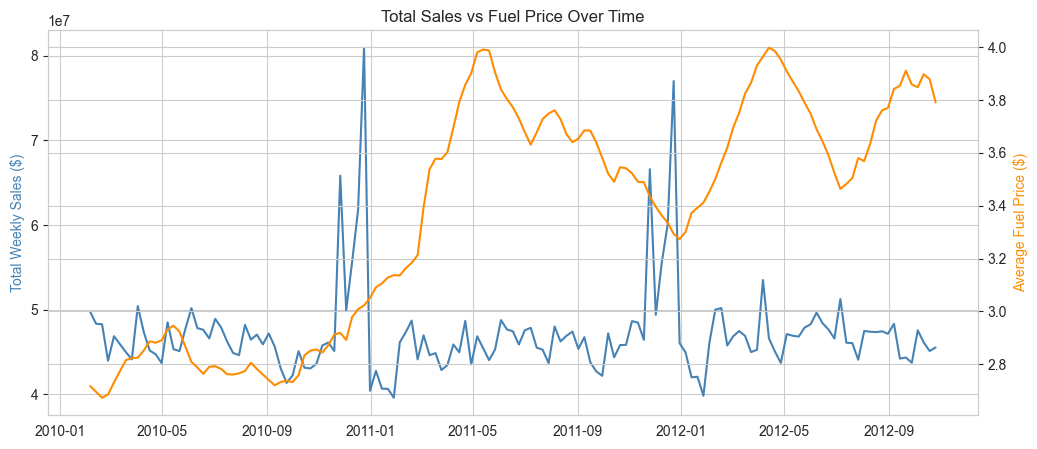

In [112]:
# Chart - 10 visualization code
weekly = df.groupby('Date').agg({'Weekly_Sales':'sum','Fuel_Price':'mean'}).reset_index()
fig, ax1 = plt.subplots(figsize=(12,5))
ax1.plot(weekly['Date'], weekly['Weekly_Sales'], color='steelblue', label='Total Sales')
ax1.set_ylabel('Total Weekly Sales ($)', color='steelblue')
ax2 = ax1.twinx()
ax2.plot(weekly['Date'], weekly['Fuel_Price'], color='darkorange', label='Avg Fuel Price')
ax2.set_ylabel('Average Fuel Price ($)', color='darkorange')
plt.title('Total Sales vs Fuel Price Over Time')
plt.show()

##### 1. Why did you pick the specific chart?

A dual-axis trend chart is the clearest way to visually compare two time series moving at different scales, showing whether fuel price and sales move together over time.

##### 2. What is/are the insight(s) found from the chart?

Fuel prices trend upward gradually over the period while sales stay range-bound with sharp holiday spikes - the two series don't visibly track each other week to week.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Suggests Fuel_Price alone has limited short-term predictive power for weekly sales, though it's still worth testing as one of several features rather than a headline driver.

#### Chart - 11

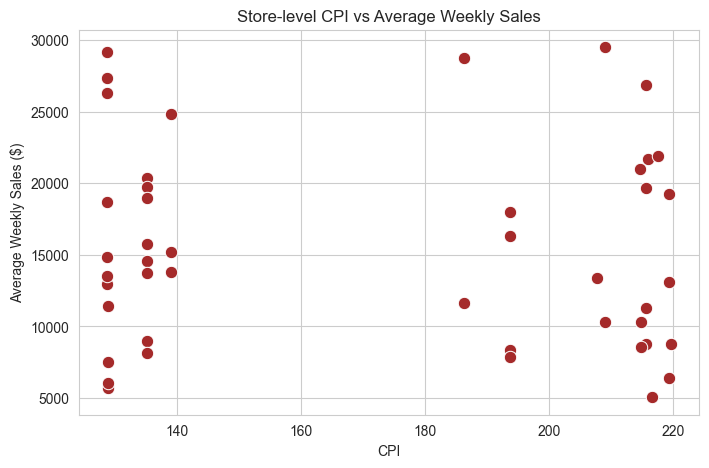

In [113]:
# Chart - 11 visualization code
store_level_cpi = df.groupby('Store').agg({'Weekly_Sales':'mean','CPI':'mean'}).reset_index()
plt.figure(figsize=(8,5))
sns.scatterplot(data=store_level_cpi, x='CPI', y='Weekly_Sales', s=80, color='brown')
plt.title('Store-level CPI vs Average Weekly Sales')
plt.xlabel('CPI')
plt.ylabel('Average Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

Aggregating to store-level before plotting CPI against sales avoids noise from week-to-week variation and shows whether regional cost-of-living differences relate to store performance.

##### 2. What is/are the insight(s) found from the chart?

Stores cluster into two visible CPI bands (likely reflecting different regions), with sales varying within each band more due to store size/type than CPI itself.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Indicates CPI mainly acts as a regional marker rather than a direct sales driver - useful context for the external-factors analysis, tempering expectations of CPI as a strong forecasting feature.

#### Chart - 12

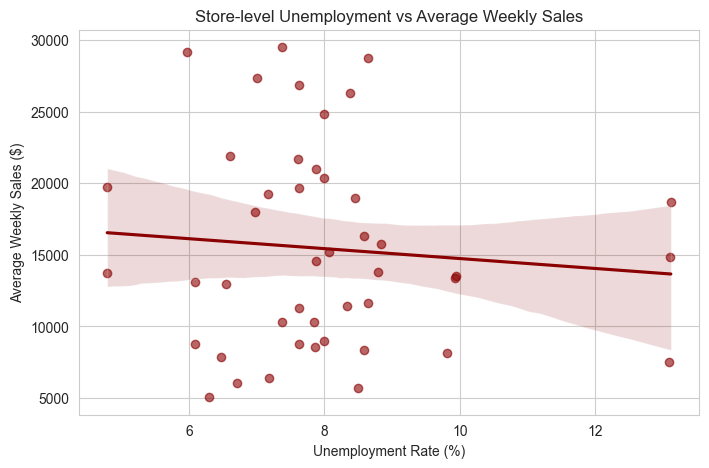

In [114]:
# Chart - 12 visualization code
store_level_unemp = df.groupby('Store').agg({'Weekly_Sales':'mean','Unemployment':'mean'}).reset_index()
plt.figure(figsize=(8,5))
sns.regplot(data=store_level_unemp, x='Unemployment', y='Weekly_Sales', scatter_kws={'alpha':0.6}, color='darkred')
plt.title('Store-level Unemployment vs Average Weekly Sales')
plt.xlabel('Unemployment Rate (%)')
plt.ylabel('Average Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

Adding a regression line to the scatter makes any directional relationship between regional unemployment and store sales easy to read at a glance.

##### 2. What is/are the insight(s) found from the chart?

There's a mild downward trend - stores in higher-unemployment regions tend to show slightly lower average sales - but the relationship is weak and store size still dominates.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - worth keeping Unemployment as a minor supporting feature in forecasting and as a factor in region-specific marketing strategy, but not as a primary driver.

#### Chart - 13

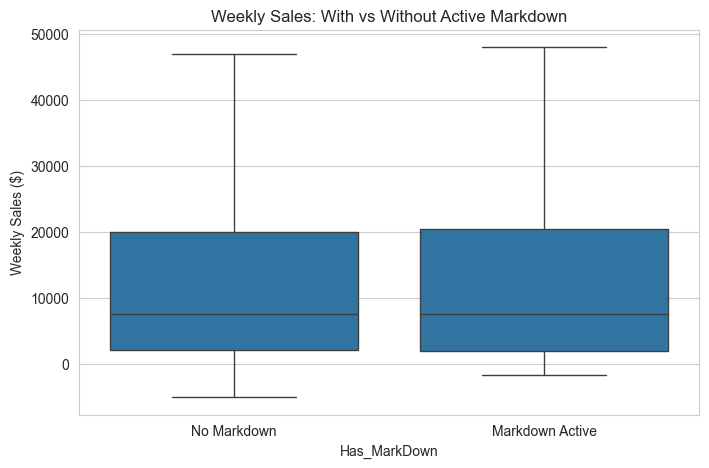

In [115]:
# Chart - 13 visualization code
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Has_MarkDown', y='Weekly_Sales', showfliers=False)
plt.xticks([0,1], ['No Markdown','Markdown Active'])
plt.title('Weekly Sales: With vs Without Active Markdown')
plt.ylabel('Weekly Sales ($)')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the full sales distribution (not just the average) between markdown-active and markdown-inactive weeks, which is more informative than a single summary bar.

##### 2. What is/are the insight(s) found from the chart?

Weeks with an active markdown promotion show a noticeably higher median and upper range of Weekly Sales compared to weeks without any markdown.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes - supports using markdowns as a deliberate promotional lever, and confirms Total_MarkDown/Has_MarkDown are worth including as forecasting features.

#### Chart - 14 - Correlation Heatmap

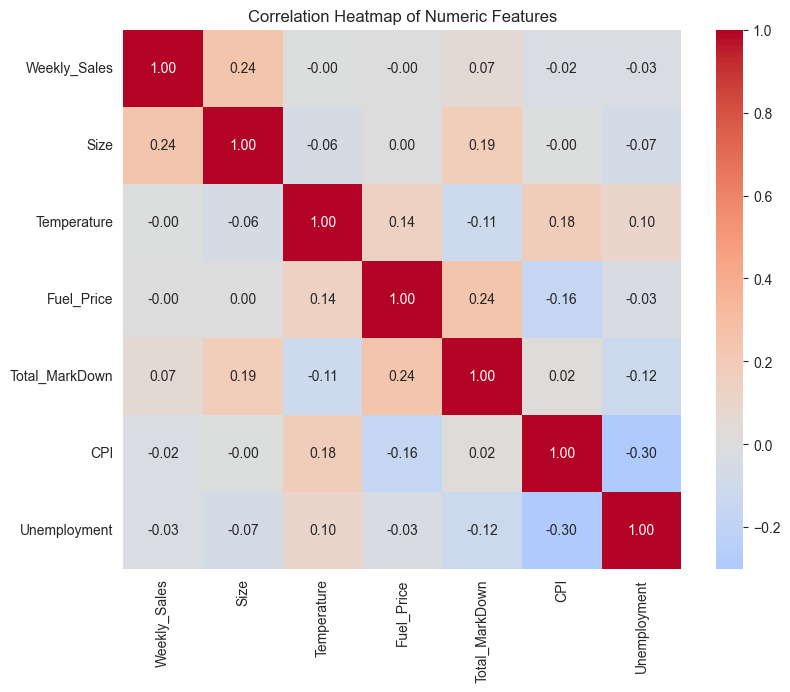

In [116]:
# Correlation Heatmap visualization code
numeric_cols = ['Weekly_Sales','Size','Temperature','Fuel_Price','Total_MarkDown','CPI','Unemployment']
plt.figure(figsize=(9,7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap is the standard way to see all pairwise correlations between numeric features at once, helping spot redundancy and candidate predictors before modeling.

##### 2. What is/are the insight(s) found from the chart?

Size correlates positively with Weekly_Sales (confirming Chart 7). Fuel_Price, Temperature, CPI, and Unemployment all show weak correlation with sales individually. No pair of features is so highly correlated with each other that one is entirely redundant, except Size acting as a proxy for Type (categorical, not shown here).

#### Chart - 15 - Pair Plot

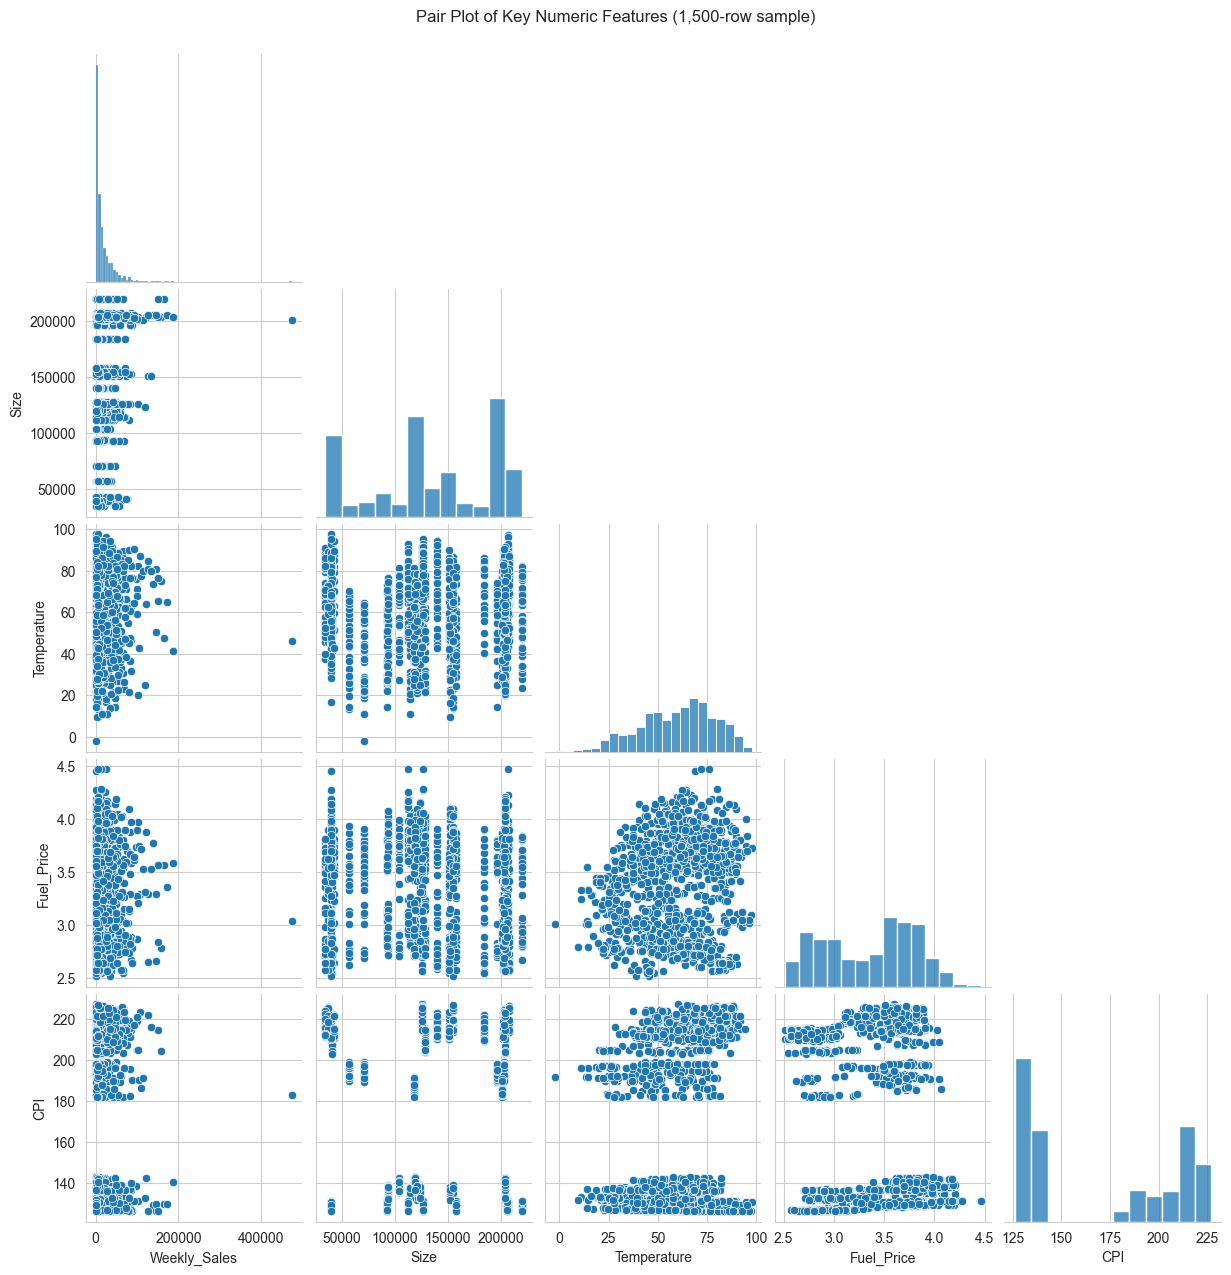

In [117]:
# Pair Plot visualization code
sample = df.sample(1500, random_state=42)
sns.pairplot(sample[['Weekly_Sales','Size','Temperature','Fuel_Price','CPI']], corner=True)
plt.suptitle('Pair Plot of Key Numeric Features (1,500-row sample)', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot extends the heatmap by showing the actual shape of each pairwise relationship, not just a single correlation number - useful for catching non-linear patterns a heatmap would miss.

##### 2. What is/are the insight(s) found from the chart?

Weekly_Sales' right-skew is visible across every pairing. No strong non-linear relationship jumps out between the macro/environmental features and sales, reinforcing that store-level factors (Size, Type, Dept) matter far more than external conditions for predicting sales magnitude.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

- Use Store Type/Size as the primary lever for store-level strategy (staffing, inventory depth) since they are the strongest sales drivers found.
- Build holiday- and month-aware inventory planning, given the clear and consistent seasonal/holiday lift.
- Treat markdown activity as a deliberate sales lever, not just a cost - weeks with active markdowns show higher sales.
- Prioritize forecasting and inventory accuracy effort on the small set of top-revenue departments identified in Chart 8.
- Use CPI/Unemployment as secondary, regional-context features rather than primary demand drivers.

# **Conclusion**

This EDA merged and cleaned 421,570 weekly Store-Dept sales records across 45 stores, engineering holiday,
seasonal, and markdown-related features. The 15 charts reveal a right-skewed sales distribution, strong
holiday/seasonal effects, a clear Store Size/Type performance hierarchy, department-level sales concentration,
and a positive markdown-sales relationship, while external macro factors (Temperature, Fuel_Price, CPI,
Unemployment) show only weak individual relationships with sales. These findings directly set up the next
phases: anomaly detection (separating expected holiday spikes from genuine outliers), segmentation (Store
Type/Size as a natural starting point), and demand forecasting (Store, Dept, Size, IsHoliday, and markdown
activity as the strongest candidate features).

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***